
# E-Commerce Data Mining and Analysis

## Project Overview
This project focuses on analyzing an online retail
transaction dataset using Python.

The objective is to understand customer purchasing
patterns, product performance, sales trends, and
business performance through data mining techniques.

## Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Dataset
Online Retail / E-Commerce Transaction Dataset


In [29]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [30]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:

df = pd.read_csv(
    '/content/drive/MyDrive/data.csv',
    encoding='latin1'
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [32]:

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())


Total Rows: 541909
Total Columns: 8

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [33]:

print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [34]:

print("Statistical Summary:")
display(df.describe())

print("\nCategorical Data Summary:")
display(df.describe(include='object'))


Statistical Summary:


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000



Categorical Data Summary:


,InvoiceNo,StockCode,Description,InvoiceDate,Country
count,541909,541909,540455,541909,541909
unique,25900,4070,4223,23260,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10/31/2011 14:41,United Kingdom
freq,1114,2313,2369,1114,495478


In [35]:

print("Missing Values in Each Column:")

missing_values = df.isnull().sum()

display(missing_values)

print("\nTotal Missing Values:",
      missing_values.sum())


Missing Values in Each Column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Total Missing Values: 136534


In [36]:

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("Missing Values Percentage:")
display(missing_percentage.round(2))


Missing Values Percentage:


,0
InvoiceNo,0.00
StockCode,0.00
Description,0.27
Quantity,0.00
InvoiceDate,0.00
UnitPrice,0.00
CustomerID,24.93
Country,0.00


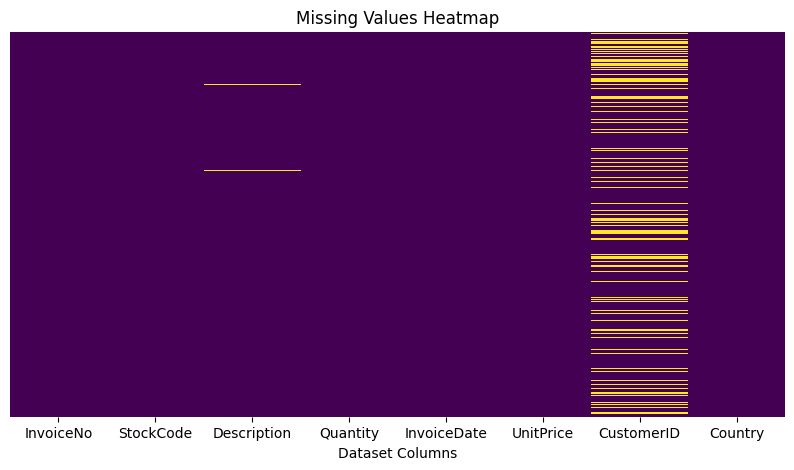

In [37]:

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Columns")
plt.show()


In [38]:

print("Total Duplicate Records:",
      df.duplicated().sum())


Total Duplicate Records: 5268


In [39]:

negative_quantity = df[df['Quantity'] < 0]

print("Negative Quantity Records:",
      len(negative_quantity))

display(negative_quantity.head(10))


Negative Quantity Records: 10624


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [40]:

negative_price = df[df['UnitPrice'] < 0]
zero_price = df[df['UnitPrice'] == 0]

print("Negative Price Records:", len(negative_price))
print("Zero Price Records:", len(zero_price))

print("\nNegative Price Details:")
display(negative_price)

print("\nZero Price Details:")
display(zero_price.head(10))


Negative Price Records: 2
Zero Price Records: 2515

Negative Price Details:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom



Zero Price Details:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,12/1/2010 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom


In [41]:

cancelled = df[
    df['InvoiceNo'].astype(str).str.startswith('C')
]

print("Cancelled Transactions:", len(cancelled))

display(cancelled.head(10))


Cancelled Transactions: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [42]:

cancelled_mask = (
    df['InvoiceNo'].astype(str).str.startswith('C')
)

negative_mask = df['Quantity'] < 0

print("Cancelled Invoices:",
      cancelled_mask.sum())

print("Negative Quantity Records:",
      negative_mask.sum())

print("Both Cancelled and Negative:",
      (cancelled_mask & negative_mask).sum())

print("Negative Quantity without C Invoice:",
      (~cancelled_mask & negative_mask).sum())


Cancelled Invoices: 9288
Negative Quantity Records: 10624
Both Cancelled and Negative: 9288
Negative Quantity without C Invoice: 1336


In [43]:

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)


Original Dataset Shape: (541909, 8)
Working Dataset Shape: (541909, 8)


In [44]:

df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'],
    format='%m/%d/%Y %H:%M',
    errors='coerce'
)

print("Date Conversion Completed!")

print("Date Data Type:",
      df_clean['InvoiceDate'].dtype)

print("Invalid Dates:",
      df_clean['InvoiceDate'].isnull().sum())

display(df_clean[['InvoiceDate']].head())


Date Conversion Completed!
Date Data Type: datetime64[ns]
Invalid Dates: 0


,InvoiceDate
0,2010-12-01 08:26:00
1,2010-12-01 08:26:00
2,2010-12-01 08:26:00
3,2010-12-01 08:26:00
4,2010-12-01 08:26:00


In [45]:

print("Duplicates Before Cleaning:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().copy()

print("Duplicates After Cleaning:",
      df_clean.duplicated().sum())

print("Updated Dataset Shape:",
      df_clean.shape)


Duplicates Before Cleaning: 5268
Duplicates After Cleaning: 0
Updated Dataset Shape: (536641, 8)


In [46]:

df_clean['Description'] = (
    df_clean['Description'].fillna('Unknown Product')
)

print("Missing Description Values:",
      df_clean['Description'].isnull().sum())

print("Missing CustomerID Values:",
      df_clean['CustomerID'].isnull().sum())


Missing Description Values: 0
Missing CustomerID Values: 135037


In [47]:

print("========== DATA QUALITY REPORT ==========")

print("Total Records:", len(df_clean))

print("Total Columns:", len(df_clean.columns))

print("Duplicate Records:",
      df_clean.duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("==========================================")


========== DATA QUALITY REPORT ==========
Total Records: 536641
Total Columns: 8
Duplicate Records: 0

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [48]:

cancelled_mask = (
    df_clean['InvoiceNo']
    .astype(str)
    .str.startswith('C')
)

returns_mask = df_clean['Quantity'] < 0

adjustment_mask = df_clean['UnitPrice'] < 0

zero_price_mask = df_clean['UnitPrice'] == 0

cancelled_data = df_clean[cancelled_mask].copy()

returns_data = df_clean[
    returns_mask & ~cancelled_mask
].copy()

adjustment_data = df_clean[adjustment_mask].copy()

zero_price_data = df_clean[zero_price_mask].copy()

print("Cancelled Transactions:", len(cancelled_data))
print("Other Negative Quantity Records:", len(returns_data))
print("Negative Price Adjustments:", len(adjustment_data))
print("Zero Price Transactions:", len(zero_price_data))


Cancelled Transactions: 9251
Other Negative Quantity Records: 1336
Negative Price Adjustments: 2
Zero Price Transactions: 2510


In [49]:

sales_data = df_clean[
    (~cancelled_mask) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Normal Sales Records:", len(sales_data))

display(sales_data.head())


Normal Sales Records: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [50]:

sales_data['TotalSales'] = (
    sales_data['Quantity'] *
    sales_data['UnitPrice']
)

print("Total Revenue:",
      round(sales_data['TotalSales'].sum(), 2))

display(sales_data.head())


Total Revenue: 10642110.8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [51]:

sales_data['Year'] = (
    sales_data['InvoiceDate'].dt.year
)

sales_data['Month'] = (
    sales_data['InvoiceDate'].dt.month
)

sales_data['MonthName'] = (
    sales_data['InvoiceDate'].dt.month_name()
)

sales_data['Day'] = (
    sales_data['InvoiceDate'].dt.day
)

sales_data['DayName'] = (
    sales_data['InvoiceDate'].dt.day_name()
)

sales_data['Hour'] = (
    sales_data['InvoiceDate'].dt.hour
)

sales_data['YearMonth'] = (
    sales_data['InvoiceDate'].dt.to_period('M').astype(str)
)

print("New Features Created Successfully!")

display(sales_data.head())


New Features Created Successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Year,Month,MonthName,Day,DayName,Hour,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December,1,Wednesday,8,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December,1,Wednesday,8,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12


In [52]:

total_revenue = sales_data['TotalSales'].sum()

total_orders = sales_data['InvoiceNo'].nunique()

total_customers = sales_data['CustomerID'].nunique()

total_products = sales_data['StockCode'].nunique()

total_quantity = sales_data['Quantity'].sum()

print("========== BUSINESS OVERVIEW ==========")

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Quantity Sold:", total_quantity)

print("=======================================")


========== BUSINESS OVERVIEW ==========
Total Revenue: 10642110.8
Total Orders: 19960
Total Customers: 4338
Total Products: 3922
Total Quantity Sold: 5572420


In [53]:

monthly_sales = (
    sales_data.groupby('YearMonth')['TotalSales']
    .sum()
    .sort_index()
)

print("Monthly Revenue:")
display(monthly_sales)


Monthly Revenue:


,TotalSales
YearMonth,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


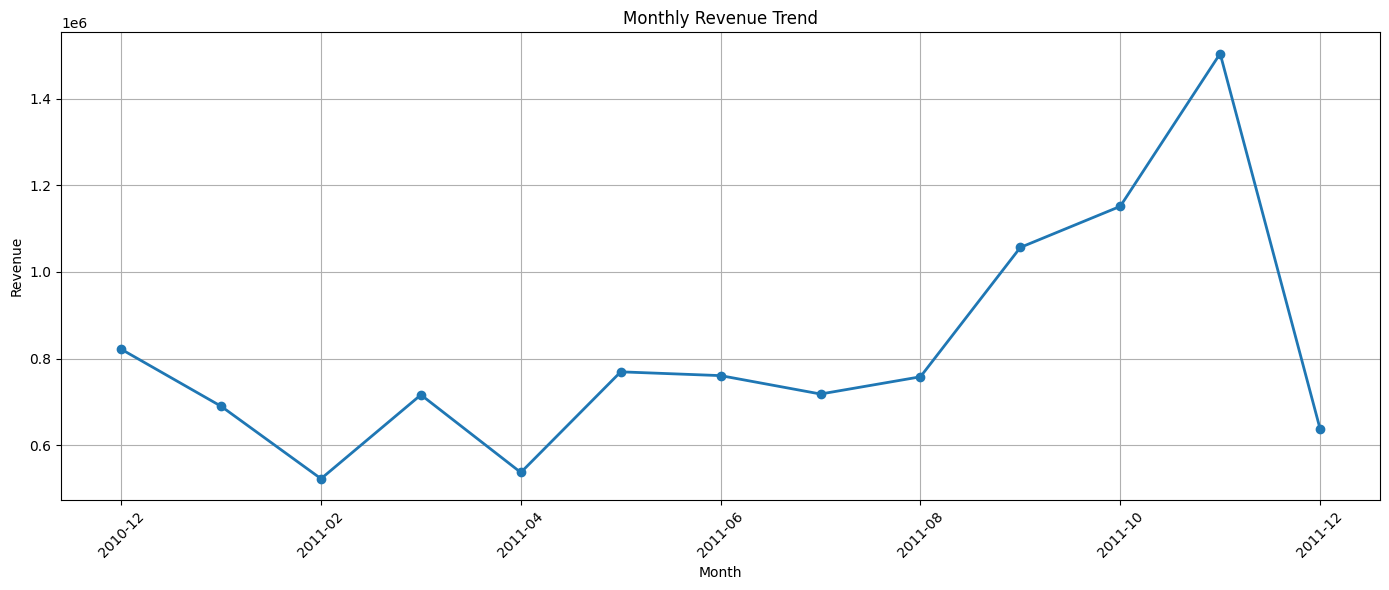

In [54]:

plt.figure(figsize=(14, 6))

monthly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [55]:

top_products = (
    sales_data.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Selling Products:")
display(top_products)


Top 10 Selling Products:


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


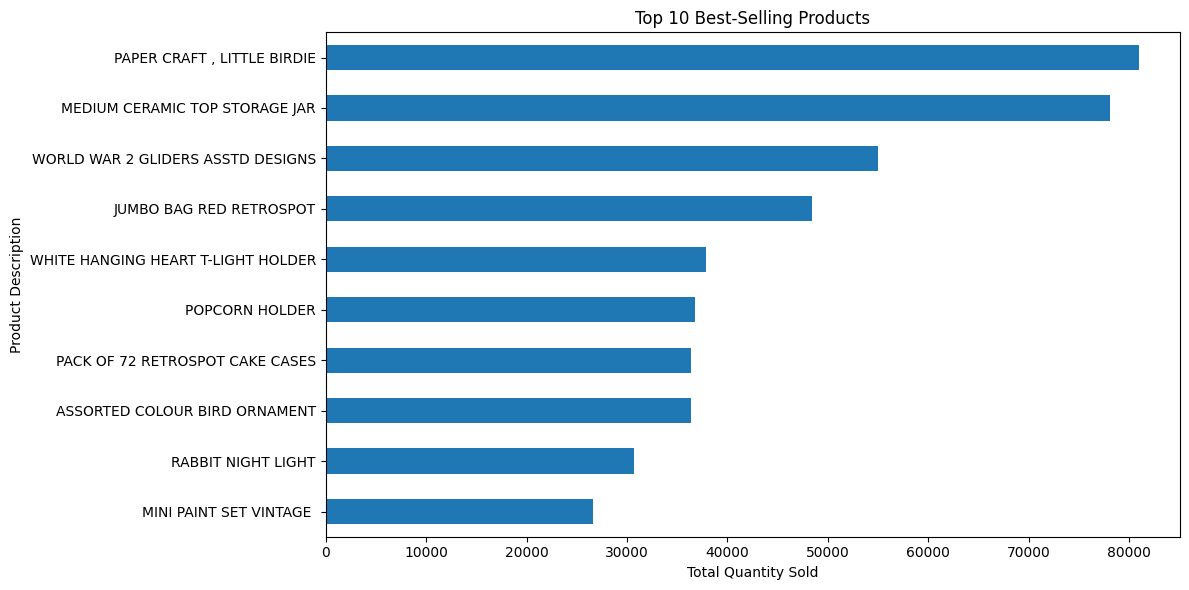

In [56]:

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind='barh'
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()


In [57]:

country_sales = (
    sales_data.groupby('Country')['TotalSales']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Revenue:")
display(country_sales.head(10))


Top 10 Countries by Revenue:


,TotalSales
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


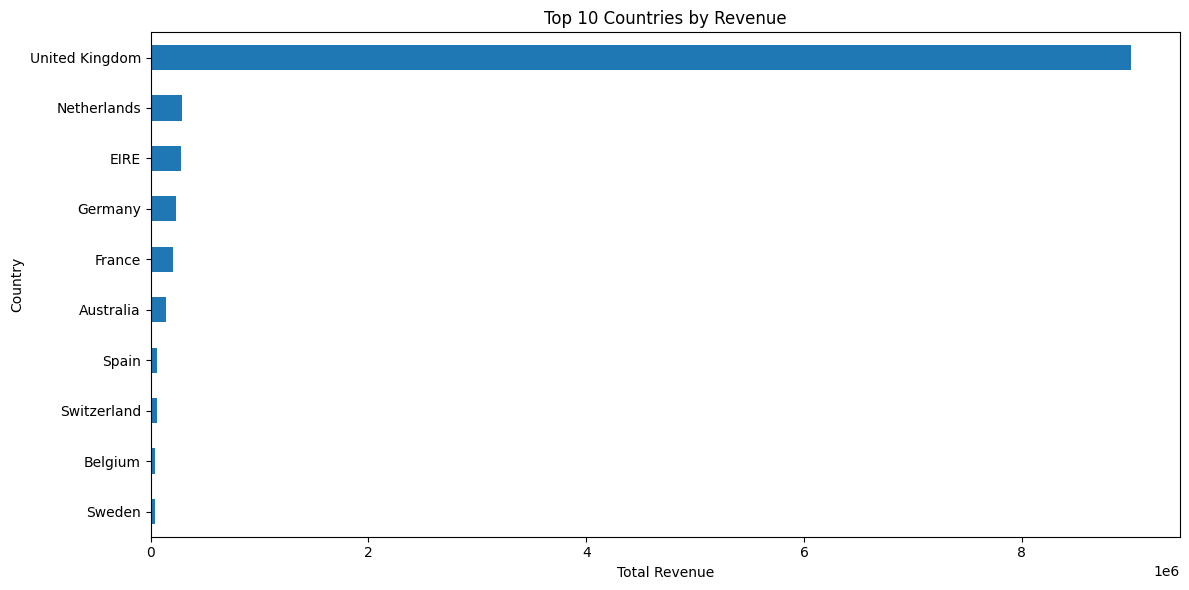

In [58]:

plt.figure(figsize=(12, 6))

country_sales.head(10).sort_values().plot(
    kind='barh'
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [59]:

daily_sales = (
    sales_data.groupby('DayName')['TotalSales']
    .sum()
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = daily_sales.reindex(day_order)

print("Day-wise Revenue:")
display(daily_sales)


Day-wise Revenue:


,TotalSales
DayName,
Monday,1775782.071
Tuesday,2175700.511
Wednesday,1847074.380
Thursday,2199292.570
Friday,1837470.491
Saturday,NaN
Sunday,806790.781


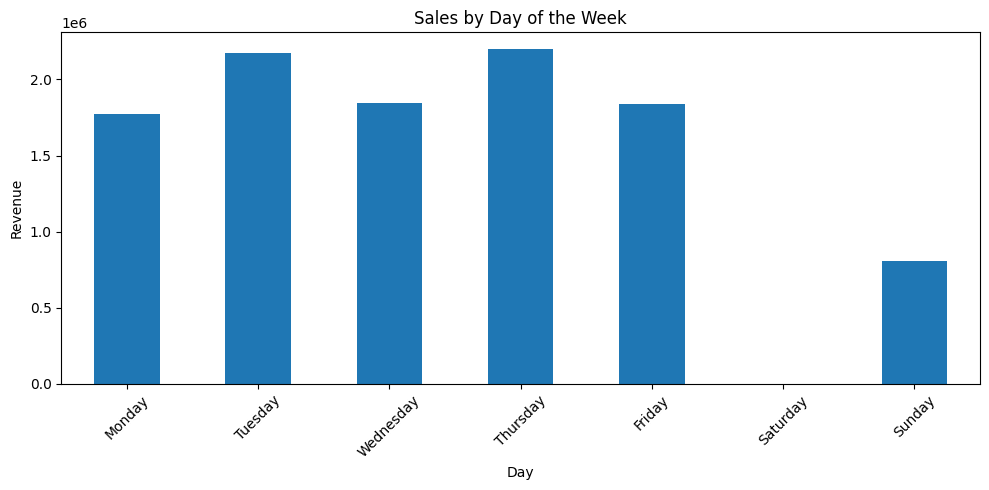

In [60]:

plt.figure(figsize=(10, 5))

daily_sales.plot(kind='bar')

plt.title("Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


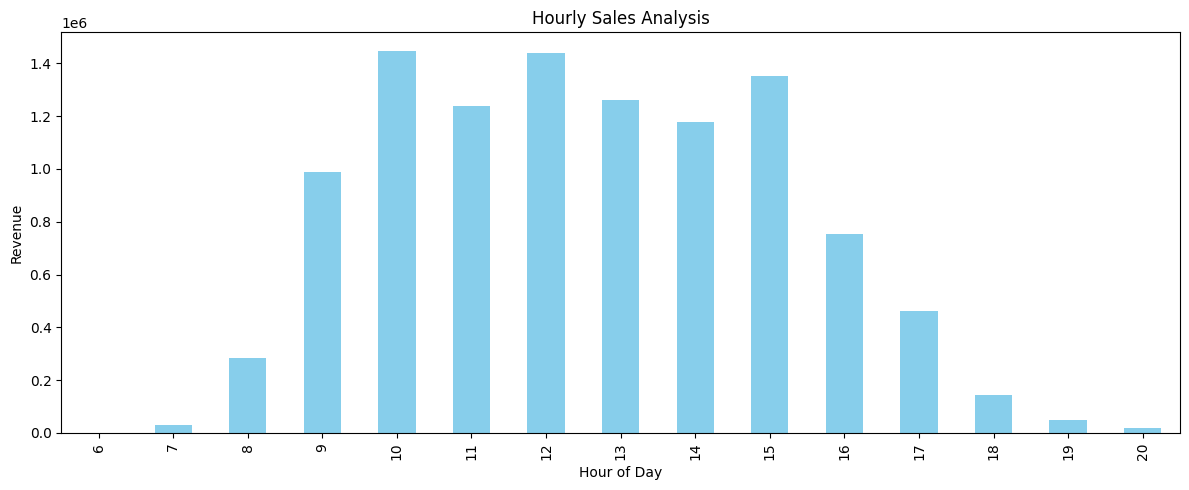

In [61]:

hourly_sales = (
    sales_data.groupby('Hour')['TotalSales']
    .sum()
)

plt.figure(figsize=(12, 5))

hourly_sales.plot(
    kind='bar',
    color='skyblue'
)

plt.title("Hourly Sales Analysis")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


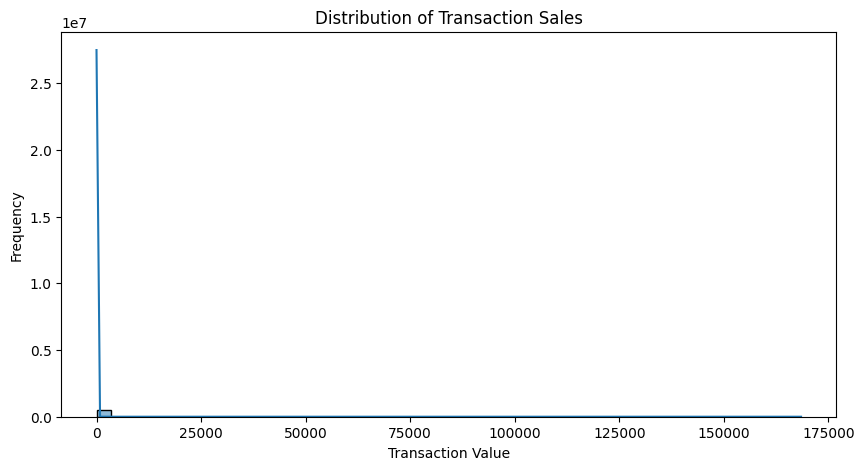

In [62]:

plt.figure(figsize=(10, 5))

sns.histplot(
    sales_data['TotalSales'],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Sales")
plt.xlabel("Transaction Value")
plt.ylabel("Frequency")
plt.show()


Correlation Matrix:


,Quantity,UnitPrice,TotalSales
Quantity,1.000000,-0.003788,0.907402
UnitPrice,-0.003788,1.000000,0.137381
TotalSales,0.907402,0.137381,1.000000


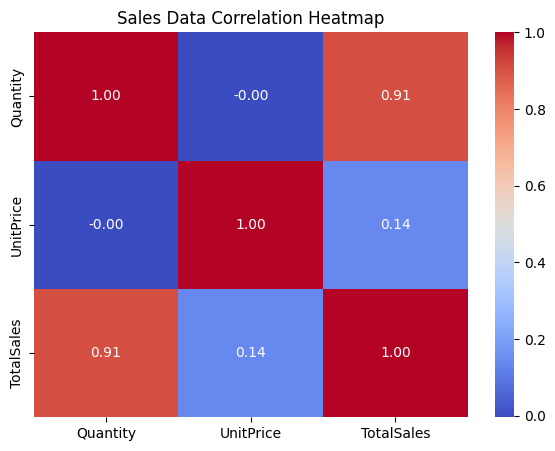

In [63]:

correlation = sales_data[
    ['Quantity', 'UnitPrice', 'TotalSales']
].corr()

print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Sales Data Correlation Heatmap")
plt.show()


In [64]:

customer_sales = (
    sales_data.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:")
display(customer_sales)


Top 10 Customers by Revenue:


,TotalSales
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


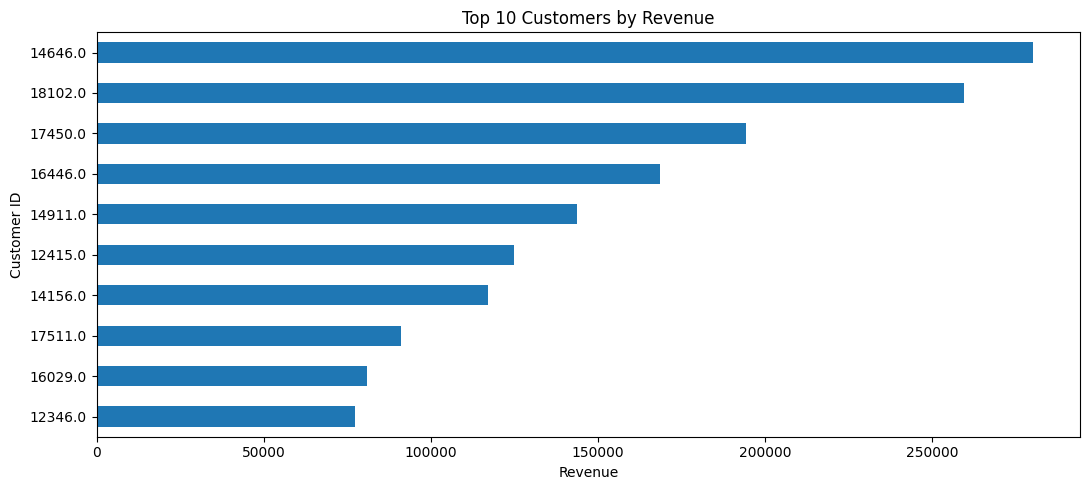

In [65]:

plt.figure(figsize=(11, 5))

customer_sales.sort_values().plot(
    kind='barh'
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


In [66]:

order_values = (
    sales_data.groupby('InvoiceNo')['TotalSales']
    .sum()
)

average_order_value = order_values.mean()

print("Average Order Value:",
      round(average_order_value, 2))

print("Highest Order Value:",
      round(order_values.max(), 2))

print("Lowest Order Value:",
      round(order_values.min(), 2))


Average Order Value: 533.17
Highest Order Value: 168469.6
Lowest Order Value: 0.38


In [67]:

top_revenue_products = (
    sales_data.groupby('Description')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(top_revenue_products)


Top 10 Products by Revenue:


,TotalSales
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


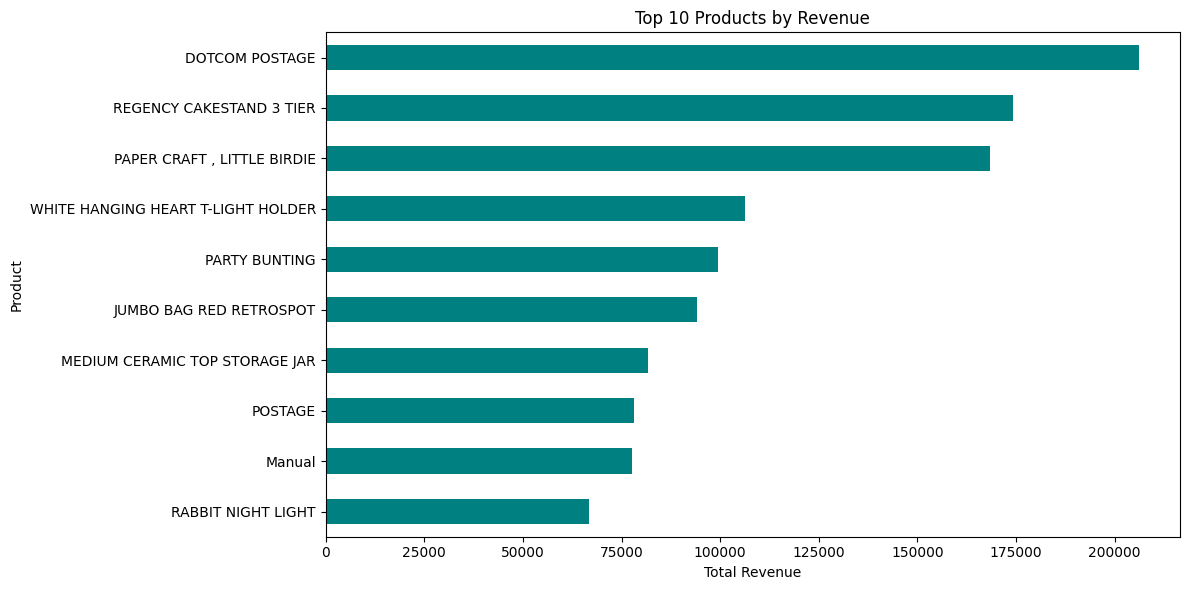

In [68]:

plt.figure(figsize=(12, 6))

top_revenue_products.sort_values().plot(
    kind='barh',
    color='teal'
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [69]:

print("========== FINAL BUSINESS ANALYSIS ==========")

print("Original Dataset Records:", len(df))

print("Cleaned Dataset Records:", len(df_clean))

print("Total Sales Transactions:", len(sales_data))

print("Total Revenue:",
      round(sales_data['TotalSales'].sum(), 2))

print("Unique Customers:",
      sales_data['CustomerID'].nunique())

print("Unique Products:",
      sales_data['StockCode'].nunique())

print("Total Orders:",
      sales_data['InvoiceNo'].nunique())

print("Top Revenue Country:",
      country_sales.index[0])

print("Top Selling Product:",
      top_products.index[0])

print("=============================================")


========== FINAL BUSINESS ANALYSIS ==========
Original Dataset Records: 541909
Cleaned Dataset Records: 536641
Total Sales Transactions: 524878
Total Revenue: 10642110.8
Unique Customers: 4338
Unique Products: 3922
Total Orders: 19960
Top Revenue Country: United Kingdom
Top Selling Product: PAPER CRAFT , LITTLE BIRDIE



# Conclusion

The E-Commerce Data Mining project was performed
using Python and its data analysis libraries.

The dataset was explored, investigated, cleaned and
processed to understand online retail transactions.

Exploratory Data Analysis was performed to identify
monthly sales trends, popular products, country-wise
revenue, customer purchasing patterns and hourly sales.

The analysis helped identify important business
patterns and provided useful insights into customer
behaviour and sales performance.

This project demonstrates how data mining and
visualization techniques can support business
decision-making.


In [71]:

df_clean.to_csv(
    '/content/cleaned_ecommerce_data.csv',
    index=False
)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!


In [72]:

sales_data.to_csv(
    '/content/ecommerce_sales_analysis.csv',
    index=False
)

print("Sales dataset exported successfully!")


Sales dataset exported successfully!


In [73]:

from google.colab import files

files.download('/content/cleaned_ecommerce_data.csv')

files.download('/content/ecommerce_sales_analysis.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>